# Generalized graded unfolding model for ranking (GGUM-RANK)

Which trait level makes a particular statement most appealing? Fit simulated
rankings to estimate the statements' ideal points, then check the fitted
endorsement curves and ranking predictions.

## Model preferences around an ideal point

Let $\theta_{p,t(j)}$ be respondent $p$'s score on the trait measured by
statement $j$. The ideal point $\delta_j$ is the trait level where the
statement is most likely to be endorsed. The signed distance on the
statement's scale is $x_{pj}=a_j(\theta_{p,t(j)}-\delta_j)$, with positive
discrimination $a_j$. The two endorsement weights are

$$
W_{pj}(1)=e^{-a_j\tau_j}\bigl(e^{x_{pj}}+e^{2x_{pj}}\bigr),
\qquad
W_{pj}(0)=1+e^{3x_{pj}}.
$$

Here $\tau_j$ is a statement threshold. The probability of endorsing the
statement is $W_{pj}(1)/[W_{pj}(1)+W_{pj}(0)]$. A larger $a_j$ makes the
endorsement curve fall more sharply away from $\delta_j$. A larger
$\tau_j$ lowers endorsement at any given trait score.

The odds of endorsement are $w_{pj}=W_{pj}(1)/W_{pj}(0)$. At each stage,
select a statement with probability proportional to its odds among
the remaining statements. For the response $Y_{pb}=(A,B,C)$, in order from most to least preferred,

$$
P(Y_{pb}=(A,B,C))=
\frac{w_{pA}}{w_{pA}+w_{pB}+w_{pC}}\,
\frac{w_{pB}}{w_{pB}+w_{pC}}.
$$

The first factor compares all three statements. The second compares only
$B$ and $C$. The figures later show statement endorsement and block
ranking probabilities on their respective scales.
[GGUM-RANK model and priors](../models/ggum_rank.md)

### Set the score scale

Each trait has mean zero and SD one. Location sides in the design set the
sign of signed ideal points. A reference threshold is fixed at zero
within each connected set of statements.

## Read the design and responses

The simulation has 200 respondents, 24 triplets, and four traits. Each design
row specifies a statement, its position and its trait. The location side
gives the sign restriction on that statement's ideal point.

In [1]:
import pandas as pd
import seaborn as sns

import pyfcirt as fc

sns.set_theme(style="ticks")

example = fc.load_example("simulated_ggum_rank", model="GGUMRank", n_persons=200)
example.data.design.head(3)

,block_id,position,statement_id,trait,keying,location_side
0,B1,1,S1,theta1,1,-1
1,B1,2,S2,theta2,1,-1
2,B1,3,S3,theta3,1,-1


Each answer lists statement positions from most to least preferred. For B1,
[2, 3, 1] orders the second statement above the third and the first.

In [2]:
example.data.responses.frame.head(3)

,person_id,block_id,response
0,1,B1,"[2, 3, 1]"
1,1,B2,"[2, 3, 1]"
2,1,B3,"[3, 2, 1]"


In [3]:
model = fc.Model()
model.add_fc(
    example.data.design,
    example.data.responses.frame,
    format="block_long",
    model="GGUMRank",
    response_format="rank",
)
model.prepare()
print(model.summary())

Model: GGUMRank
200 people, 4 traits, 24 blocks, 72 statements
Observations: 4,800 block events
Measurements:
  rank: 24 blocks, size=3, categories=6
Population:
  theta ~ MvNormal(mu=0, cov=R)
  R [4 x 4] ~ LKJCorr(n=4, eta=1)
Priors:
    loading [72] ~ LogNormal(mu=0, sigma=0.25)
    statement_threshold [48] ~ Normal(mu=0, sigma=2)
    location (location_negative) [36] ~ TruncatedNormal(mu=-2, sigma=1, lower=-inf, upper=0)
    location (location_positive) [36] ~ TruncatedNormal(mu=2, sigma=1, lower=0, upper=inf)
Constraints:
    statement_threshold: fixed=0 [24 fixed]


The summary lists full ranking events and the priors for positive and negative locations.

## Fit the model

The estimates shown use four chains with 2,000 warmup iterations and
1,500 retained draws per chain. [Estimation backend setup](../examples/estimation_backends.md)

In [4]:
model.fit(draws=1500, tune=2000, chains=4);

## Diagnose the chains

The maximum R-hat is 1.008. The minimum bulk and tail effective sample sizes
are 875 and 988, and there are zero divergences.

In [5]:
import arviz as az
import numpy as np

posterior = model.idata.posterior.to_dataset().reset_coords(drop=True)
with np.errstate(invalid="ignore", divide="ignore"):
    r_hat = az.rhat(posterior).max().to_array().max().item()
    bulk = az.ess(posterior, method="bulk").min().to_array().min().item()
    tail = az.ess(posterior, method="tail").min().to_array().min().item()

print(f"Max R-hat: {r_hat:.3f}")
print(f"Min bulk / tail ESS: {bulk:.0f} / {tail:.0f}")
print("Divergences:", int(model.idata.sample_stats.diverging.sum()))

Max R-hat: 1.008
Min bulk / tail ESS: 875 / 988
Divergences: 0


The density and rank plots compare chains for respondent 1 on the first
trait. The rank-test p-value for this score is 0.18.

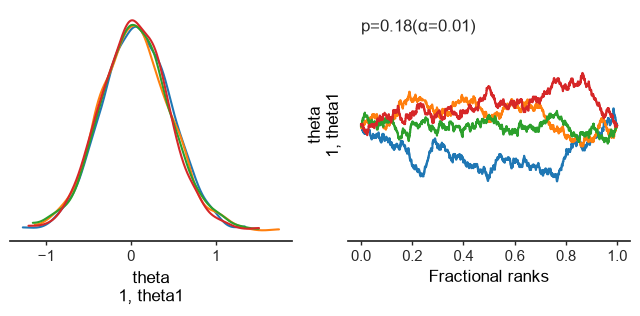

In [6]:
import arviz_plots as azp
import matplotlib.pyplot as plt

with sns.color_palette("tab10"):
    azp.plot_rank_dist(
        model.idata,
        var_names=["theta"],
        coords={"person": [1], "trait": ["theta1"]},
        compact=False,
        backend="matplotlib",
        figure_kwargs={"figsize": (8, 3)},
    )
    plt.show()

## Read the statement estimates

The B1 table shows each statement's discrimination, ideal point and threshold.
The last two columns give 95% highest-density intervals. S1's estimated ideal
point is −1.91, and its interval runs from −3.59 to −0.69. The fixed reference
threshold shows zero with blank uncertainty cells.
The negative locations follow the design's sign restriction for B1.

In [7]:
coef = model.coef(blocks=["B1"], kind="stats", round_to=2)
columns = ["statement", "parameter", "mean", "sd", "hdi95_lb", "hdi95_ub"]
table = coef.reset_index()[columns]
table.style.hide(axis="index").format(precision=2, na_rep="")

statement,parameter,mean,sd,hdi95_lb,hdi95_ub
S1,loading,0.83,0.15,0.56,1.12
S2,loading,1.06,0.20,0.68,1.46
S3,loading,1.13,0.20,0.75,1.54
S1,statement_threshold,0.00,,,
S2,statement_threshold,-2.15,0.90,-3.98,-0.35
S3,statement_threshold,0.10,0.87,-1.61,1.89
S1,location,-1.91,0.79,-3.59,-0.69
S2,location,-1.57,0.70,-2.97,-0.42
S3,location,-2.50,0.66,-3.86,-1.34


These curves compare four statements on theta1 using their posterior-mean
parameters. S1 peaks near −1.91. Its fixed zero threshold puts the peak
at 0.50 on the reference endorsement scale. A whole ranking depends on
the other statements' odds as well.

The bottom marks show respondents' posterior mean scores. The gray band
spans the middle 90% of those scores.

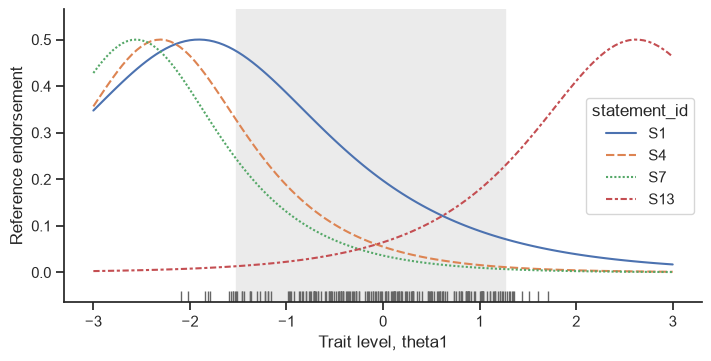

In [8]:
import jax.numpy as jnp
from jax.nn import sigmoid

statements = example.data.design.query("trait == 'theta1'")
statements = statements.statement_id.drop_duplicates().head(4)
estimates = model.coef(
    var_names=["loading", "location", "statement_threshold"],
    kind="stats",
).reset_index()
point = estimates.pivot(index="statement", columns="parameter", values="mean").loc[statements]

theta_grid = jnp.linspace(-3, 3, 121)
a = jnp.asarray(point.loading.to_numpy())
delta = jnp.asarray(point.location.to_numpy())
threshold = jnp.asarray(point.statement_threshold.to_numpy())
x = a * (theta_grid[:, None] - delta)
log_odds = jnp.logaddexp(x, 2 * x) - a * threshold - jnp.logaddexp(0, 3 * x)
curves = pd.DataFrame(sigmoid(log_odds), index=theta_grid, columns=statements)
scores = model.idata.posterior.theta.sel(trait="theta1").mean(("chain", "draw"))
low, high = scores.quantile([0.05, 0.95]).values

fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.axvspan(low, high, color="0.92")
sns.lineplot(data=curves, ax=ax)
sns.rugplot(x=scores.values, height=0.04, color="0.4", ax=ax)
ax.set(xlabel="Trait level, theta1", ylabel="Reference endorsement")
sns.despine(fig=fig)
plt.show()

## Check the predicted rankings

Compare the frequencies of the six observed B1 orders with 200 sets of
replicated rankings. Crosses mark observed proportions. Dots mark predictive
means, and the lines show 95% predictive intervals.

In [9]:
predictions = model.posterior_predictive(draws=200, random_seed=44)
view = fc.predictive_view(predictions, block="B1")

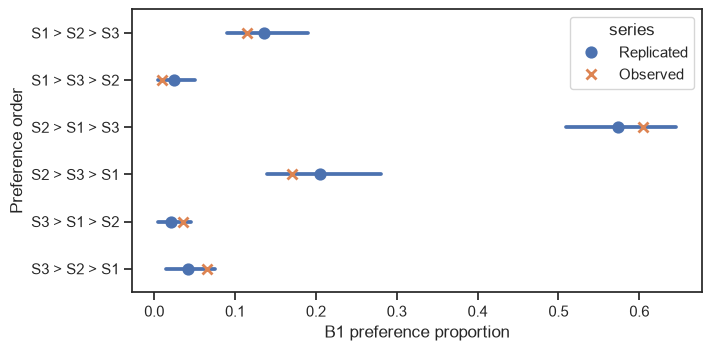

In [10]:
from itertools import permutations

import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr

statements = example.data.design.query("block_id == 'B1'").sort_values("position")
orders = [" > ".join(order) for order in permutations(statements.statement_id)]
category = xr.DataArray(range(len(orders)), dims="order", coords={"order": orders})


def order_proportions(answers, series):
    share = (answers == category).mean("obs")
    return share.to_dataframe(name="proportion").reset_index().assign(series=series)


proportions = pd.concat(
    [
        order_proportions(view.posterior_predictive.response, "Replicated"),
        order_proportions(view.observed_data.response, "Observed"),
    ]
)
fig, ax = plt.subplots(figsize=(7, 3.4), layout="constrained")
sns.pointplot(
    proportions,
    x="proportion",
    y="order",
    hue="series",
    order=orders,
    markers=["o", "x"],
    linestyles="none",
    errorbar=("pi", 95),
    ax=ax,
)
ax.set(xlabel="B1 preference proportion", ylabel="Preference order")
plt.show()

The Pearson check measures mismatch across all 200 B1 rankings. Its
posterior predictive p-value is 0.325, the share of replicated discrepancies
at least as large as the observed one.

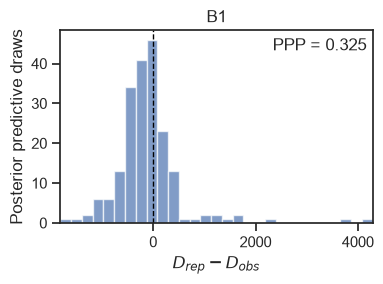

In [11]:
check = model.chi_ppp(predictions=predictions, blocks=["B1"], groupby="block")
fc.plot_ppp(check, quantile_range=(0.005, 0.995))
plt.show()

## Read score precision

Empirical reliability ranges from 0.748 to 0.790 for the four traits in
this simulation. It summarizes score precision across respondents.

In [12]:
reliability = model.reliability()["reliability"].to_series()
reliability.round(3).to_frame("Reliability")

,Reliability
trait,
theta1,0.790
theta2,0.767
theta3,0.748
theta4,0.763


The ridge plot compares respondents 1, 2 and 3. Markers show posterior means
and lines show 50% and 95% HDIs. Compare their widths before interpreting
small differences between scores.

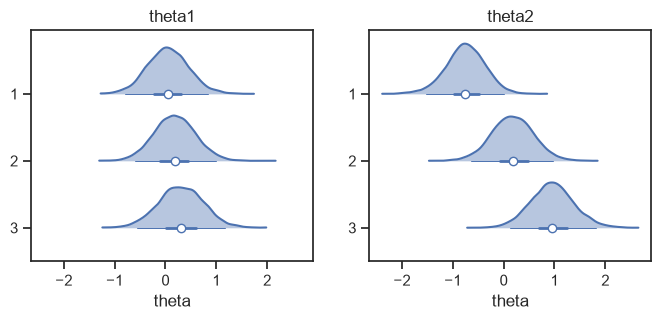

In [13]:
fc.plot_ridge(
    model.idata,
    coords={"person": [1, 2, 3], "trait": ["theta1", "theta2"]},
    max_rows=3,
    col_wrap=2,
    figsize=(8, 3),
)
plt.show()

See the [GGUM-RANK mathematical notes](../models/ggum_rank.md) for equations
linking the endorsement odds to ranking probabilities.

## References

Lee, P., Joo, S.-H., Stark, S., & Chernyshenko, O. S. (2019). GGUM-RANK statement and person parameter estimation with multidimensional forced choice triplets. *Applied Psychological Measurement, 43*(3), 226–240. [https://doi.org/10.1177/0146621618768294](https://doi.org/10.1177/0146621618768294).
